## 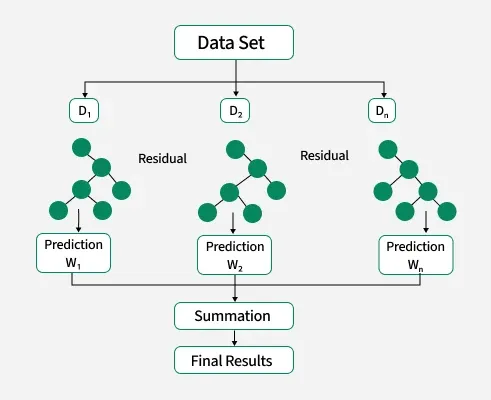

In [2]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   - -------------------------------------- 2.1/72.0 MB 14.7 MB/s eta 0:00:05
   --- ------------------------------------ 5.8/72.0 MB 16.8 MB/s eta 0:00:04
   ---- ----------------------------------- 8.9/72.0 MB 16.3 MB/s eta 0:00:04
   ------- -------------------------------- 13.6/72.0 MB 18.2 MB/s eta 0:00:04
   --------- ------------------------------ 16.8/72.0 MB 17.3 MB/s eta 0:00:04
   ---------- ----------------------------- 18.6/72.0 MB 16.3 MB/s eta 0:00:04
   ----------- ---------------------------- 20.7/72.0 MB 15.0 MB/s eta 0:00:04
   ------------ --------------------------- 23.3/72.0 MB 14.8 MB/s eta 0:00:04
   -------------- ------------------------- 26.0/72.0 MB 14.5 MB/s eta 0:00:04
   --------------- ------------------------ 28.6/72.0 MB 14.3 MB/s eta 0:00:04
   ----------------- ---------------------- 31.2/72.0 MB 14.1 MB/

**Step 1: Importing necessary libraries**

In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

**Step 2: Loading and splitting the dataset**

In [8]:
df = pd.read_csv('Data/Churn_Modelling.csv')
X = df.iloc[:, 3:13]
y = df.iloc[:, 13].values

**Step 3: Converting categorical Columns**

In [9]:
X['Geography'] = X['Geography'].astype('category')
X['Gender'] = X['Gender'].astype('category')

**Step 4: Splitting the dataset into training and testing**

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25, random_state =0)

**Step 5: Converting Dataset into DMatrix**

In [13]:
xgb_train = xgb.DMatrix(X_train, y_train, enable_categorical=True)
xgb_test = xgb.DMatrix(X_test, y_test, enable_categorical = True)

**Step 6: Creating XGboost Model**

In [14]:
params = {
    'objective':'binary:logistic',
    'max_depth':3,
    'learning_rate':0.1,
}
n=50
model = xgb.train(params = params, dtrain=xgb_train, num_boost_round=n)

**Step 7: Making Predictions and Evaluating the Model**

In [16]:
preds = model.predict(xgb_test)
preds = np.round(preds)
accuracy = accuracy_score(y_test, preds)
print('Accuracy of the model is:', accuracy*100)

Accuracy of the model is: 86.83999999999999
